# 06 · Fase 5: selección, explicabilidad y evaluación

**Primera entrega: preparación y análisis de validation. Sin ejecutar en esta plantilla.**
Runtime GPU nuevo. Se restauran best.pt; no se entrena. Conservar los notebooks
02/03/04/05 ejecutados y sus outputs. Este notebook guarda resultados nuevos.

El test interno y los externos siguen reservados. Esta versión no contiene
ninguna celda de inferencia sobre test, ni una opción que la active.
Antes de añadir esa evaluación se deben congelar selección, pesos,
preprocesamiento, umbrales, NMS y regla de concordancia con sus hashes.

Flujo actual: preparación → comparación validation → smoke de carga separado
→ umbrales del clasificador → diagnóstico del detector → concordancia exploratoria.
Explicabilidad, incertidumbre, decisión final, congelamiento y evaluación reservada
se incorporarán después de revisar estas salidas. Fase 5 aún no completa.

## Fase 5 · Paso 1 — Drive y paquete aislado

El archivo `tbx11k_fase5_preparacion_colab.zip` debe estar en
`MyDrive/Proyecto_Tuberculosis/`. No extraer encima del proyecto anterior.
Cada ejecución de esta celda crea otra carpeta de resultados; conserve sus salidas
y guarde este notebook con Ctrl+S. No se incluyen datos ni pesos en el ZIP.

In [1]:
import hashlib, importlib, json, stat, subprocess, sys, uuid, zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
from google.colab import drive
drive.mount('/content/drive')
DRIVE_BASE = Path('/content/drive/MyDrive/Proyecto_Tuberculosis')
ARCHIVE = DRIVE_BASE / 'tbx11k_fase5_preparacion_colab.zip'
EXPECTED_PACKAGE_SHA256 = '99d402b198d5ab1a2a023ebcb1b87e62c45905e132d42daf3d55aa8bed84f96c'
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
if file_sha256(ARCHIVE) != EXPECTED_PACKAGE_SHA256:
    raise ValueError('ZIP diferente de esta versión del notebook. Use ambos archivos de la misma entrega.')
RUN_ID = 'phase5_validation_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
PROJECT_ROOT = Path('/content/tbx11k_phase5') / RUN_ID
PROJECT_ROOT.mkdir(parents=True, exist_ok=False)
with zipfile.ZipFile(ARCHIVE) as archive:
    names = archive.namelist()
    if len(names) != len(set(names)): raise ValueError('ZIP con nombres duplicados.')
    for item in archive.infolist():
        rel = PurePosixPath(item.filename)
        target = (PROJECT_ROOT / item.filename).resolve()
        if (rel.is_absolute() or '..' in rel.parts or ':' in item.filename
                or chr(92) in item.filename or stat.S_ISLNK(item.external_attr >> 16)
                or PROJECT_ROOT.resolve() not in target.parents):
            raise ValueError('Ruta ZIP insegura: '+item.filename)
    checksums = json.loads(archive.read('phase5_package_checksums.json'))
    if set(names) != set(checksums) | {'phase5_package_checksums.json'}:
        raise ValueError('Cobertura de checksums incorrecta.')
    for name, expected in checksums.items():
        if hashlib.sha256(archive.read(name)).hexdigest() != expected: raise ValueError(name)
    archive.extractall(PROJECT_ROOT)
for name in list(sys.modules):
    if name in {'tbxdata','tbxtrain','_tbx_official_vmamba','_tbx_official_scan'} or name.startswith(('tbxdata.','tbxtrain.')):
        del sys.modules[name]
sys.path.insert(0, str(PROJECT_ROOT/'src'))
from tbxtrain.protocol import atomic_json
OUT = DRIVE_BASE / 'results/phase5' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
atomic_json(OUT/'session.json', dict(run_id=RUN_ID, package_sha256=EXPECTED_PACKAGE_SHA256,
    scope='validation_only', test_evaluated=False, external_evaluated=False,
    decisions_frozen=False, phase5_complete=False))
print('Resultados nuevos:', OUT)

Mounted at /content/drive
Resultados nuevos: /content/drive/MyDrive/Proyecto_Tuberculosis/results/phase5/phase5_validation_20261103T042954Z_bc33c6


## Fase 5 · Paso 2 — Dependencias y runtime

Se conservan torch/torchvision/torchaudio instalados; si las dependencias no
son compatibles, pip debe fallar antes de reemplazarlos. No cambie CUDA a ciegas.
La preparación de selective scan se ejecuta en el paso 5 solo si hace falta.

In [2]:
import importlib.metadata as metadata
import torch
if not torch.cuda.is_available(): raise RuntimeError('Seleccione GPU en Colab.')
protected = {}
for name in ['torch','torchvision','torchaudio']:
    try: protected[name] = metadata.version(name)
    except metadata.PackageNotFoundError: pass
constraints = PROJECT_ROOT/'runtime_constraints.txt'
constraints.write_text(''.join(name+'=='+version+'\n' for name,version in protected.items()))
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
    '-c', str(constraints), '-r', str(PROJECT_ROOT/'requirements-phase5.txt')])
if any(metadata.version(k) != v for k,v in protected.items()):
    raise RuntimeError('Se alteró el runtime protegido. Reinicie antes de continuar.')
import pandas as pd
from IPython.display import display
environment = dict(python=sys.version, torch=torch.__version__, cuda=torch.version.cuda,
    gpu=torch.cuda.get_device_name(0), packages={d.metadata['Name']:d.version for d in metadata.distributions()})
atomic_json(OUT/'environment.json', environment)
torch.manual_seed(20261019)
torch.cuda.manual_seed_all(20261019)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
print('Python:',sys.version.split()[0], '| torch:',torch.__version__, '| CUDA:',torch.version.cuda,
      '| GPU:',torch.cuda.get_device_name(0))

Python: 3.13.16 | torch: 2.11.0+cu130 | CUDA: 13.0 | GPU: NVIDIA L4


## Fase 5 · Paso 3 — Procedencia, pesos y comparación de validation

Verifica los SHA de best.pt, las fuentes originales registradas, configuración,
manifiestos y las 1.241 predicciones por modelo. Añadir `phase5.py` no altera
el código original de entrenamiento. Cualquier divergencia detiene la ejecución.
El ranking sigue siendo una candidatura; no congela la selección ni los umbrales.

In [3]:
from tbxdata.common import sha256, write_csv
from tbxdata.validate import validate_manifests
from tbxtrain.phase5 import (CLASSES, validation_rows, verify_classifier,
    restore_classifier, tb_threshold_table, detector_threshold_table, concordance)
CONFIG = json.loads((PROJECT_ROOT/'configs/phase5_preparation.json').read_text())
integrity = validate_manifests(PROJECT_ROOT)
ROWS = validation_rows(PROJECT_ROOT)
if len(ROWS) != 1241: raise ValueError('Validation distinta del protocolo.')
CACHE, summaries, comparison = {}, [], []
for spec in CONFIG['classifiers']:
    summary, predictions, y, p, metrics = verify_classifier(PROJECT_ROOT, DRIVE_BASE, spec, ROWS)
    summaries.append(summary)
    CACHE[spec['architecture']] = (predictions, y, p)
    comparison.append(dict(architecture=spec['architecture'], run_id=spec['run_id'],
        epoch=summary['best_epoch'], accuracy=metrics['accuracy'], macro_f1=metrics['macro_f1'],
        TB_recall=metrics['per_class']['TB']['recall'], TB_specificity=metrics['per_class']['TB']['specificity'],
        checkpoint_sha256=spec['sha256']))
if any(s['provenance'] != summaries[0]['provenance'] for s in summaries):
    raise ValueError('Procedencia no comparable entre modelos.')
DET_SPEC = CONFIG['detector']
DET_FOLDER = DRIVE_BASE/'experiments'/DET_SPEC['run_id']
DET_WEIGHTS = DET_FOLDER/'training/weights/best.pt'
DET_SHA256 = sha256(DET_WEIGHTS)
DET_SUMMARY = json.loads((DET_FOLDER/'detector_summary.json').read_text())
if DET_SUMMARY['status'] != 'trained_validation_available' or DET_SUMMARY['test_evaluated']:
    raise ValueError('Estado del detector fuera del protocolo.')
# El hash del detector no se publicó en el cierre previo: se registra como
# baseline de bytes actuales, no se presenta como verificación histórica.
atomic_json(OUT/'artifact_verification.json', dict(classifiers=comparison,
    detector=dict(run_id=DET_SPEC['run_id'], observed_sha256=DET_SHA256,
        hash_status='observed_now_no_prior_reference', summary=DET_SUMMARY),
    manifest_integrity=integrity, test_evaluated=False))
write_csv(OUT/'validation_comparison.csv', comparison)
display(pd.DataFrame(comparison).sort_values('macro_f1', ascending=False))
CANDIDATE = max(comparison, key=lambda r:r['macro_f1'])['architecture']
print('Candidato por Macro-F1 de validation:', CANDIDATE, '| Sin congelar.')

,architecture,run_id,epoch,accuracy,macro_f1,TB_recall,TB_specificity,checkpoint_sha256
2,hybrid_cross_attention,phase3_hybrid_cross_attention_20261103T032205Z...,3,0.978243,0.964470,0.891667,0.996432,1db1965bd191456cec05f9d91a45539e7dcc22bfbbab0a...
1,vmamba_tiny,phase3_vmamba_tiny_20261103T025536Z_4784e4,11,0.968574,0.949672,0.841667,0.996432,56efbe2bc8230f7fb52cc199d89489f98134bb2364cc06...
0,convnext_tiny,phase3_convnext_tiny_20261103T023002Z_4a7e2a,11,0.970991,0.942716,0.783333,0.997324,33869c4791569f95c262df2987c9a688649aa4f65c92e5...


Candidato por Macro-F1 de validation: hybrid_cross_attention | Sin congelar.


### Fase 5 · Paso 3.1 — Exportar gráficos para el informe

Genera **12 figuras** desde las tres corridas y el detector: comparación de
clasificadores; entrenamiento de cada clasificador (pérdida, accuracy,
Macro-F1/sensibilidad TB, mejor época); matrices con conteos y normalización por
clase real; ROC OVR por modelo; ROC y precisión–recall TB comparativas;
pérdidas, mAP y P/R del detector. No reentrena ni altera las salidas originales.

Cada figura se guarda en **PNG 300 dpi, PDF y SVG**, con CSV de datos,
un índice README y un manifiesto de hashes/fuentes. Cada repetición de esta celda
genera otra carpeta, conservando las exportaciones anteriores. Los gráficos
de entrenamiento proceden de los historiales previos; no son entrenamientos nuevos.

In [4]:
from tbxtrain.phase5_figures import export_validation_figures
from IPython.display import Image
FIGURES_DIR = OUT / ('figures_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6])
figure_manifest_path = export_validation_figures(PROJECT_ROOT,DRIVE_BASE,
    CONFIG['classifiers'],FIGURES_DIR,detector_run_id=DET_SPEC['run_id'])
figure_manifest = json.loads(figure_manifest_path.read_text())
for entry in figure_manifest['figures']:
    print(entry['title'])
    display(Image(filename=str(FIGURES_DIR/(entry['name']+'.png')),width=1000))
print('Figuras y tablas para el informe:', FIGURES_DIR)

Output hidden; open in https://colab.research.google.com to view.

## Fase 5 · Paso 4 — Datos y verificación de transferencia

Reutiliza el lector RGB 512, letterbox y normalización ImageNet, sin aumentos.
La verificación SHA de todos los archivos puede leer bytes de conjuntos reservados;
solo comprueba integridad. No decodifica sus imágenes ni ejecuta inferencia sobre ellos.

In [5]:
from tbxdata.colab import stage_dataset
from tbxdata.dataset import TBXDataset
source = DRIVE_BASE/'TBX11K.zip'
if not source.exists(): source = DRIVE_BASE/'TBX11K'
DATASET_ROOT = stage_dataset(source, Path('/content/tbx11k_phase5_data_cache'), True)
transfer = validate_manifests(PROJECT_ROOT, DATASET_ROOT, all_image_hashes=True)
atomic_json(OUT/'transfer_integrity.json', transfer)
VAL_DATASET = TBXDataset(DATASET_ROOT, PROJECT_ROOT/'manifests/validation.csv',
                         PROJECT_ROOT/'configs/data.json', training=False)
print('Integridad:',transfer['status'],'| Archivos verificados:',transfer['all_image_hashes_verified'])

Integridad: passed | Archivos verificados: 12278


## Fase 5 · Paso 5 — Selective scan oflex

Reutiliza el kernel si está activo. En runtime nuevo, el instalador reparado
conserva torch/CUDA y aplica compatibilidad CUDA 13. Guarda un log nuevo aquí.
El instalador reutiliza/verifica el ImageNet ya existente en `pretrained/`;
restaurar best.pt después usa `pretrained=False`. Si falla, deténgase en esta celda.

In [6]:
if importlib.util.find_spec('selective_scan_cuda_oflex') is None:
    command = [sys.executable, '-u', str(PROJECT_ROOT/'scripts/setup_vmamba_colab.py'),
               '--project', str(PROJECT_ROOT), '--drive-base', str(DRIVE_BASE)]
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    with (OUT/'vmamba_setup.log').open('w') as log:
        for line in process.stdout:
            print(line,end='',flush=True); log.write(line); log.flush()
    if process.wait(): raise RuntimeError('Falló oflex. Revisar vmamba_setup.log antes de continuar.')
    importlib.invalidate_caches()
from tbxtrain.architectures import scan_backend
backend = scan_backend()
if backend != 'oflex': raise RuntimeError('Se requiere oflex; reinicie si antes se importó el fallback.')
atomic_json(OUT/'scan_backend.json',dict(backend=backend))
print('Selective scan:', backend)

Compilador CUDA seleccionado: /usr/local/cuda/bin/nvcc release 13.0
Compilando selective scan: una tarea, un hilo nvcc y salida detallada.
{
  "nvcc_threads": 1,
  "cpp_standard": "17",
  "upstream_setup_sha256": "7386f668b4e177136f4629ebc3e2b78f2afe54e6e8c960b01f80f4c0005edcd2",
  "patched_setup_sha256": "4fefd5a59a10dca1d5347d3dfc18b5fca52cea9d3fcfab59479a62480546a814",
  "cub_compatibility": {
    "patch": "cuda13_cub_helpers_v1",
    "upstream_reverse_scan_sha256": "4b770c5890104d771f9c22ae56767700dc76d5d71b81cee70e2b88d54d2c315b",
    "patched_reverse_scan_sha256": "6510d9b8c6d8fe1383ed4d6bdffef838e4d446e9e9727f7c8baf33bcbe118331",
    "reference": "https://github.com/NVIDIA/cccl/blob/v2.8.2/cub/cub/util_ptx.cuh"
  }
}
Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing ./tbx_vmamba_build/2ed52ead062a51a64521ed3871d52914bf532876/VMamba-2ed52ead062a51a64521ed3871d52914bf532876/kernels/selective_scan
  Preparing metadata (pyproject.toml): start

/content/tbx11k_phase5/phase5_validation_20261103T042954Z_bc33c6/vendor/vmamba/vmamba.py:839: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/content/tbx11k_phase5/phase5_validation_20261103T042954Z_bc33c6/vendor/vmamba/vmamba.py:854: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd


Selective scan: oflex


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/content/tbx11k_phase5/phase5_validation_20261103T042954Z_bc33c6/vendor/vmamba/csms6s.py:73: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/content/tbx11k_phase5/phase5_validation_20261103T042954Z_bc33c6/vendor/vmamba/csms6s.py:90: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd


## Fase 5 · Paso 6 — Smoke separado de carga e inferencia

Tres imágenes fijas de validation (primera por clase), una arquitectura a la vez.
Carga estricta de la mejor época; sin entrenamiento. Compara con las probabilidades
históricas como diagnóstico de runtime, con tolerancia numérica explícita.
Estas tres imágenes no constituyen una evaluación nueva de rendimiento o coste.

In [7]:
import gc, numpy as np
indices = [next(i for i,r in enumerate(ROWS) if r['class_name']==c) for c in CLASSES]
smoke_records = []
for spec in CONFIG['classifiers']:
    model = restore_classifier(PROJECT_ROOT, DRIVE_BASE, spec)
    with torch.inference_mode():
        x = torch.stack([torch.from_numpy(VAL_DATASET[i][0]) for i in indices]).cuda()
        probs = model(x).softmax(1).cpu().numpy()
    if probs.shape != (3,3) or not np.isfinite(probs).all(): raise ValueError('Forward inválido.')
    reference = CACHE[spec['architecture']][2][indices]
    delta = float(np.abs(probs-reference).max())
    passed = bool(np.allclose(probs, reference, atol=1e-3, rtol=1e-3))
    smoke_records.append(dict(architecture=spec['architecture'], passed=passed,
        max_probability_delta=delta, probabilities=probs.tolist(),
        paths=[ROWS[i]['relative_path'] for i in indices]))
    atomic_json(OUT/'load_smoke.json', smoke_records)
    del model, x; gc.collect(); torch.cuda.empty_cache()
    if not passed: raise RuntimeError('Divergencia de inferencia. Revisar runtime antes de continuar.')
display(pd.DataFrame(smoke_records)[['architecture','passed','max_probability_delta']])

,architecture,passed,max_probability_delta
0,convnext_tiny,True,0.000021
1,vmamba_tiny,True,0.000571
2,hybrid_cross_attention,True,0.000047


## Fase 5 · Paso 7 — Umbrales de alerta TB en validation

Exporta todos los puntos distintos de p_TB. Se conserva argmax y cada probabilidad
original. La alerta `p_TB >= t` es una salida adicional; no convierte por sí sola
la predicción multiclase ni demuestra un objetivo clínico. No se elige un umbral
automático: revisar sensibilidad, especificidad, falsos negativos y carga de revisión.

,threshold,tp,fp,fn,tn,sensitivity,specificity,precision,alerts
0,0.05,111,6,9,1115,0.925000,0.994648,0.948718,117
1,0.10,111,5,9,1116,0.925000,0.995540,0.956897,116
2,0.20,109,4,11,1117,0.908333,0.996432,0.964602,113
3,0.30,107,4,13,1117,0.891667,0.996432,0.963964,111
4,0.50,107,4,13,1117,0.891667,0.996432,0.963964,111
5,0.70,106,3,14,1118,0.883333,0.997324,0.972477,109
6,0.90,100,1,20,1120,0.833333,0.999108,0.990099,101


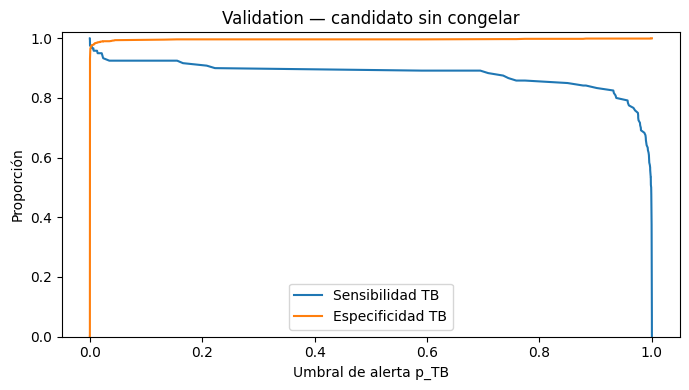

In [8]:
import matplotlib.pyplot as plt
predictions, y, p = CACHE[CANDIDATE]
THRESHOLDS = tb_threshold_table(y, p)
write_csv(OUT/'classifier_TB_thresholds_validation.csv', THRESHOLDS)
write_csv(OUT/'candidate_validation_predictions.csv', predictions)
curve = pd.DataFrame(THRESHOLDS)
display(pd.DataFrame(tb_threshold_table(y, p, [0.05,0.1,0.2,0.3,0.5,0.7,0.9])))
fig,ax = plt.subplots(figsize=(7,4))
ax.plot(curve.threshold, curve.sensitivity, label='Sensibilidad TB')
ax.plot(curve.threshold, curve.specificity, label='Especificidad TB')
ax.set(xlabel='Umbral de alerta p_TB',ylabel='Proporción',ylim=(0,1.02),title='Validation — candidato sin congelar')
ax.legend(); fig.tight_layout()
for extension in ['png','pdf','svg']:
    fig.savefig(OUT/('classifier_thresholds.'+extension),dpi=300,bbox_inches='tight')
plt.show(); plt.close(fig)

## Fase 5 · Paso 8 — Detector: diagnóstico opcional de validation

`RUN_DETECTOR_VALIDATION=False` permite terminar primero la preparación.
Al activarlo, ejecuta solo las rutas de validation, incluidas negativas y salidas
sin cajas. Coordenadas xyxy originales. Confianza mínima 0,001; NMS IoU=0,7,
máximo 300, 512px, FP32, rect=False: estos parámetros son parte del futuro contrato.
La tabla solo permite umbrales >=0,001. El matching de lesiones es greedy por
confianza con IoU>=0,5, uno a uno. No reemplaza mAP de Ultralytics.

In [9]:
RUN_DETECTOR_VALIDATION = False
DET_PREDICTIONS = None
if RUN_DETECTOR_VALIDATION:
    from ultralytics import YOLO
    if sha256(DET_WEIGHTS) != DET_SHA256: raise ValueError('El detector cambió desde la verificación.')
    detector = YOLO(str(DET_WEIGHTS))
    if detector.names != {0:'tb_lesion'}: raise ValueError('Clases inesperadas en el detector.')
    DET_PREDICTIONS = {}
    detector_options = dict(imgsz=512,conf=0.001,iou=0.7,max_det=300,
        device=0,half=False,rect=False,augment=False,save=False,verbose=False)
    from tbxdata.common import safe_path
    for offset in range(0,len(ROWS),8):
        batch = ROWS[offset:offset+8]
        results = detector.predict(source=[str(safe_path(DATASET_ROOT,r['relative_path'])) for r in batch],
                                   **detector_options)
        if len(results) != len(batch): raise ValueError('Batch detector incompleto.')
        for row,result in zip(batch,results):
            if Path(result.path).resolve() != safe_path(DATASET_ROOT,row['relative_path']):
                raise ValueError('Orden de imágenes detector inconsistente.')
            DET_PREDICTIONS[row['relative_path']] = [dict(xyxy=xy,confidence=float(score))
                for xy,score in zip(result.boxes.xyxy.cpu().tolist(),result.boxes.conf.cpu().tolist())]
        if offset % 160 == 0: print('Detector validation:',min(offset+8,len(ROWS)),'/',len(ROWS),flush=True)
    atomic_json(OUT/'detector_validation_predictions.json', DET_PREDICTIONS)
    atomic_json(OUT/'detector_inference_options.json', detector_options)
    det_table = detector_threshold_table(ROWS,DET_PREDICTIONS,[0.001,0.01,0.05,0.1,0.2,0.3,0.5,0.7,0.9])
    write_csv(OUT/'detector_thresholds_validation.csv',det_table)
    display(pd.DataFrame(det_table))
    det_curve = pd.DataFrame(det_table)
    fig,axes = plt.subplots(1,2,figsize=(11,4.5))
    axes[0].plot(det_curve.threshold,det_curve.image_sensitivity_any_box,'o-',label='Imagen: cualquier caja')
    axes[0].plot(det_curve.threshold,det_curve.image_sensitivity_localized,'o-',label='Imagen: lesión localizada')
    axes[0].plot(det_curve.threshold,det_curve.lesion_recall,'o-',label='Recall por lesión')
    axes[0].set(xlabel='Umbral de confianza',ylabel='Proporción',ylim=(0,1.02),title='Detector · validation')
    axes[0].legend(fontsize=8)
    axes[1].plot(det_curve.fp_boxes_per_image,det_curve.lesion_recall,'o-')
    for row in det_table:
        axes[1].annotate(str(row['threshold']),(row['fp_boxes_per_image'],row['lesion_recall']),fontsize=8)
    axes[1].set(xlabel='FP/caja por imagen (todas las imágenes)',ylabel='Recall por lesión',
                ylim=(0,1.02),title='Matching IoU >= 0,5 · umbrales exploratorios')
    fig.tight_layout()
    for extension in ['png','pdf','svg']:
        fig.savefig(OUT/('detector_thresholds.'+extension),dpi=300,bbox_inches='tight')
    plt.show(); plt.close(fig)
    del detector; gc.collect(); torch.cuda.empty_cache()
else:
    print('Diagnóstico nuevo de detector pendiente. El resumen previo permanece disponible:',DET_SUMMARY)

Diagnóstico nuevo de detector pendiente. El resumen previo permanece disponible: {'status': 'trained_validation_available', 'map50_95': 0.21577616090176216, 'map50': 0.48423225059138064, 'validation_only': True, 'test_evaluated': False, 'phase5_complete': False}


## Fase 5 · Paso 9 — Concordancia exploratoria y discrepancias

Los valores 0,5 / 0,25 son ejemplos editables, **no decisiones finales**.
Regla propuesta: ambas alertas; solo clasificador → revisión; solo detector →
revisión; ninguna alerta → registrar ambas salidas sin afirmar ausencia de TB.
Se conservan probabilidades y cajas; nunca se multiplican sus scores.
Revisar falsos negativos, falsos positivos y discrepancias antes de adoptar la regla.

In [10]:
EXAMPLE_CLASSIFIER_THRESHOLD = 0.5
EXAMPLE_DETECTOR_THRESHOLD = 0.25
if DET_PREDICTIONS is not None:
    concordance_rows = []
    for original in predictions:
        path = original['relative_path']
        flags = concordance(float(original['p_TB']), DET_PREDICTIONS[path],
            EXAMPLE_CLASSIFIER_THRESHOLD, EXAMPLE_DETECTOR_THRESHOLD)
        concordance_rows.append(dict(**original, **flags,
            classifier_threshold=EXAMPLE_CLASSIFIER_THRESHOLD, detector_threshold=EXAMPLE_DETECTOR_THRESHOLD,
            boxes_json=json.dumps(DET_PREDICTIONS[path]), decision_status='exploratory_not_frozen'))
    write_csv(OUT/'concordance_exploratory_validation.csv',concordance_rows)
    frame = pd.DataFrame(concordance_rows)
    display(pd.crosstab(frame['label'],frame['state']))
    display(frame[frame.state.isin(['classifier_only_review','detector_only_review'])].head(20))
else:
    print('Concordancia pendiente: ejecutar diagnóstico del detector primero.')

Concordancia pendiente: ejecutar diagnóstico del detector primero.


## Fase 5 · Paso 10 — Cierre de esta preparación; test reservado

Faltan: revisión visual de cajas y errores con selección explícita; coste medido
con protocolo comparable; incertidumbre por grupos de duplicados (no pacientes);
Grad-CAM con comprobación de gradientes y comportamiento en cada rama aplicable;
elegir y justificar umbrales y regla; decidir si mejorar el detector baseline.
Los mapas visuales por sí solos no validan lesiones. La comparación usa una seed
y validation reutilizada, por lo que no prueba superioridad estadística.

Después se creará un contrato inmutable con pesos, código, preprocesamiento,
umbrales y concordancia, evidencia de validation y hashes. Solo entonces se añadirá
la evaluación reservada y el informe/exportación final. No existe desbloqueo de
test en esta versión. No se evalúan externos sin revisar procedencia y etiquetas.

In [11]:
atomic_json(OUT/'preparation_status.json', dict(status='validation_preparation_executed',
    candidate=CANDIDATE, detector_diagnostics_executed=DET_PREDICTIONS is not None,
    decisions_frozen=False, test_evaluated=False, external_evaluated=False, phase5_complete=False,
    pending=['error_and_box_visual_review','cost_protocol','group_uncertainty','verified_explainability',
             'final_selection','threshold_selection','concordance_selection','immutable_freeze',
             'reserved_evaluation','final_report_and_export']))
print('Preparación guardada:', OUT)
print('Guarde este notebook ejecutado con Ctrl+S. Test y externos siguen reservados.')

Preparación guardada: /content/drive/MyDrive/Proyecto_Tuberculosis/results/phase5/phase5_validation_20261103T042954Z_bc33c6
Guarde este notebook ejecutado con Ctrl+S. Test y externos siguen reservados.
